# Regresión Logística

## ¿Cuál es el objetivo de la Regresión Logística?

A pesar de su nombre, la **Regresión Logística** no es un algoritmo de regresión, sino de **clasificación**. Su objetivo es predecir la **probabilidad** de que una observación pertenezca a una clase determinada (típicamente 0 o 1).

La idea central es tomar una combinación lineal de las features y transformarla mediante la **función sigmoide** para obtener un valor entre 0 y 1 que interpretamos como probabilidad:

$$
\hat{y} = \sigma(\mathbf{w} \cdot \mathbf{x} + b) = \frac{1}{1 + e^{-(\mathbf{w} \cdot \mathbf{x} + b)}}
$$

Donde:

- $\hat{y}$: probabilidad predicha de pertenecer a la clase 1.
- $\mathbf{w}$: vector de pesos (weights).
- $\mathbf{x}$: vector de features de la observación.
- $b$: sesgo (bias).
- $\sigma$: función sigmoide.

La decisión final se toma con un **umbral** (threshold), generalmente 0.5:

$$
\text{clase} = \begin{cases} 1 & \text{si } \hat{y} > 0.5 \\ 0 & \text{si } \hat{y} \leq 0.5 \end{cases}
$$

A diferencia de KNN (que es lazy), la Regresión Logística **sí aprende un modelo** durante el entrenamiento: encuentra los valores óptimos de $\mathbf{w}$ y $b$ mediante **descenso de gradiente**.

**Supongamos un conjunto de datos simples**

Tomemos estos datos de estudiantes donde queremos predecir si aprueban (1) o no (0) según sus horas de estudio:

| Horas de estudio | Aprobó |
|-----------------|--------|
| 0.5             | 0      |
| 1.0             | 0      |
| 1.5             | 0      |
| 2.0             | 0      |
| 3.0             | 0      |
| 4.0             | 1      |
| 4.5             | 1      |
| 5.0             | 1      |
| 5.5             | 1      |
| 6.0             | 1      |

Visualmente, hay una transición entre las dos clases. La regresión logística busca encontrar la curva sigmoide que mejor separe ambos grupos.

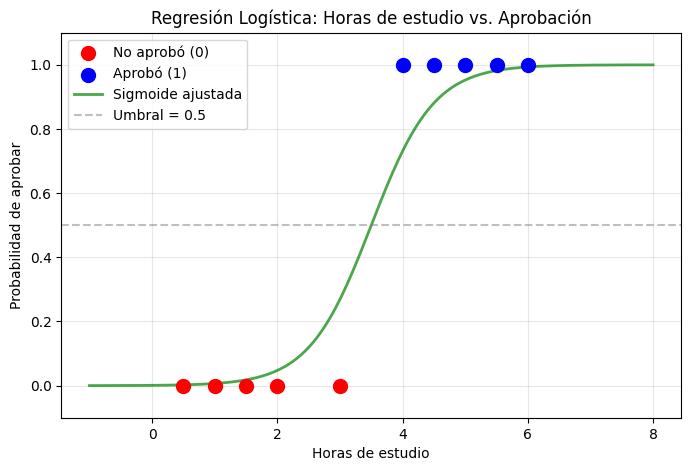

In [3]:
import matplotlib.pyplot as plt
import numpy as np

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Datos de ejemplo
horas = np.array([0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 4.5, 5.0, 5.5, 6.0])
aprobado = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

plt.figure(figsize=(8, 5))
plt.scatter(horas[aprobado == 0], aprobado[aprobado == 0], color='red', label='No aprobó (0)', s=100, zorder=5)
plt.scatter(horas[aprobado == 1], aprobado[aprobado == 1], color='blue', label='Aprobó (1)', s=100, zorder=5)

# Curva sigmoide ajustada visualmente
x_line = np.linspace(-1, 8, 200)
# Sigmoide con w=2, b=-7 (ajustada para que la transición esté ~3.5)
y_line = 1 / (1 + np.exp(-(2 * x_line - 7)))
plt.plot(x_line, y_line, 'g-', linewidth=2, label='Sigmoide ajustada', alpha=0.7)
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, label='Umbral = 0.5')

plt.xlabel('Horas de estudio')
plt.ylabel('Probabilidad de aprobar')
plt.title('Regresión Logística: Horas de estudio vs. Aprobación')
plt.ylim(-0.1, 1.1)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## ¿Por qué no usar Regresión Lineal para clasificación?

Antes de entender la regresión logística, es natural preguntarse: **¿por qué no simplemente usar regresión lineal y poner un umbral?**

El problema es que la regresión lineal puede producir valores **fuera del rango [0, 1]**, lo cual no tiene sentido como probabilidad. Además, es muy sensible a valores extremos (outliers) que distorsionan la recta.

La solución es "comprimir" la salida lineal al rango $[0, 1]$ usando la **función sigmoide**. Esto nos da una interpretación probabilística natural.

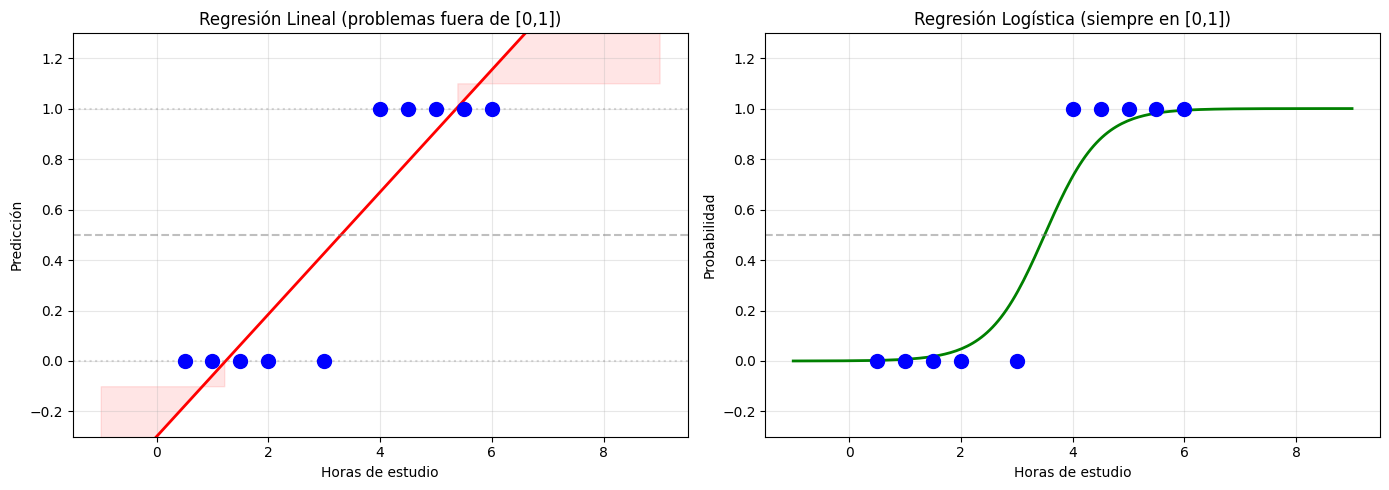

In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

horas = np.array([0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 4.5, 5.0, 5.5, 6.0])
aprobado = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

# --- Regresión Lineal ---
# Ajuste lineal simple
m = np.polyfit(horas, aprobado, 1)
x_range = np.linspace(-1, 9, 200)
y_linear = m[0] * x_range + m[1]

axes[0].scatter(horas, aprobado, color='blue', s=100, zorder=5)
axes[0].plot(x_range, y_linear, 'r-', linewidth=2)
axes[0].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
axes[0].axhline(y=0, color='gray', linestyle=':', alpha=0.3)
axes[0].axhline(y=1, color='gray', linestyle=':', alpha=0.3)
axes[0].fill_between(x_range, 1.1, y_linear, where=(y_linear > 1), alpha=0.1, color='red')
axes[0].fill_between(x_range, -0.1, y_linear, where=(y_linear < 0), alpha=0.1, color='red')
axes[0].set_ylim(-0.3, 1.3)
axes[0].set_xlabel('Horas de estudio')
axes[0].set_ylabel('Predicción')
axes[0].set_title('Regresión Lineal (problemas fuera de [0,1])')
axes[0].grid(True, alpha=0.3)

# --- Regresión Logística ---
y_logistic = 1 / (1 + np.exp(-(2 * x_range - 7)))

axes[1].scatter(horas, aprobado, color='blue', s=100, zorder=5)
axes[1].plot(x_range, y_logistic, 'g-', linewidth=2)
axes[1].axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
axes[1].set_ylim(-0.3, 1.3)
axes[1].set_xlabel('Horas de estudio')
axes[1].set_ylabel('Probabilidad')
axes[1].set_title('Regresión Logística (siempre en [0,1])')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Demostración Matemática

### Paso 1: La función sigmoide

La pieza clave de la regresión logística es la **función sigmoide** (también llamada función logística):

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Sus propiedades importantes son:

- **Rango**: siempre produce valores en $(0, 1)$, ideal para probabilidades.
- **Monótona creciente**: a mayor $z$, mayor $\sigma(z)$.
- **Punto medio**: $\sigma(0) = 0.5$.
- **Derivada simple**: $\sigma'(z) = \sigma(z)(1 - \sigma(z))$, lo cual facilita el cálculo del gradiente.

En nuestro modelo, $z$ es la combinación lineal:

$$
z = \mathbf{w} \cdot \mathbf{x} + b = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b
$$

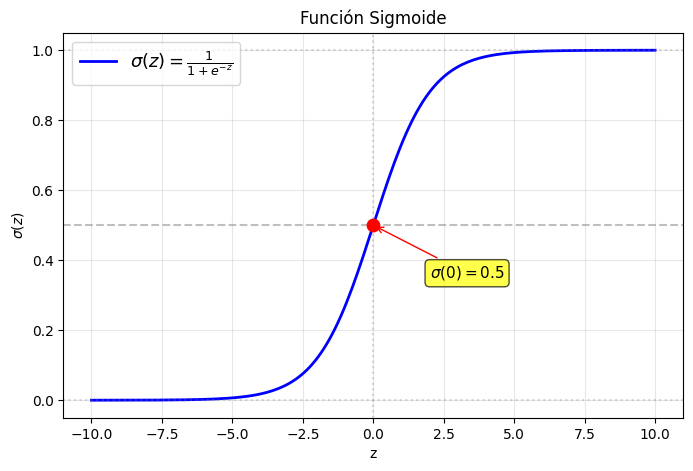

In [5]:
import matplotlib.pyplot as plt
import numpy as np

z = np.linspace(-10, 10, 200)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid, 'b-', linewidth=2, label=r'$\sigma(z) = \frac{1}{1 + e^{-z}}$')
plt.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=0, color='gray', linestyle=':', alpha=0.3)
plt.axhline(y=1, color='gray', linestyle=':', alpha=0.3)
plt.axvline(x=0, color='gray', linestyle=':', alpha=0.3)
plt.scatter([0], [0.5], color='red', s=80, zorder=5)
plt.annotate('$\sigma(0) = 0.5$', xy=(0, 0.5), xytext=(2, 0.35),
             fontsize=11, arrowprops=dict(arrowstyle='->', color='red'),
             bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7))
plt.xlabel('z')
plt.ylabel('$\sigma(z)$')
plt.title('Función Sigmoide')
plt.grid(True, alpha=0.3)
plt.legend(fontsize=13)
plt.show()

### Paso 2: La función de costo (Log-Loss / Binary Cross-Entropy)

Para entrenar el modelo, necesitamos una función que mida **qué tan mal** están nuestras predicciones. En regresión logística usamos la **Binary Cross-Entropy** (también llamada Log-Loss):

$$
J(\mathbf{w}, b) = -\frac{1}{n} \sum_{i=1}^{n} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]
$$

Donde $\hat{y}_i = \sigma(\mathbf{w} \cdot \mathbf{x}_i + b)$.

**¿Por qué esta función y no el error cuadrático medio (MSE)?**

El MSE combinado con la sigmoide crea una superficie de costo **no convexa** con muchos mínimos locales. La cross-entropy, en cambio, produce una función **convexa**, lo que garantiza que el descenso de gradiente encuentre el mínimo global.

**Intuición de la función de costo:**

- Si $y_i = 1$ y $\hat{y}_i \approx 1$: $-\log(1) \approx 0$ → costo bajo ✓
- Si $y_i = 1$ y $\hat{y}_i \approx 0$: $-\log(0) \to \infty$ → costo muy alto ✗
- Si $y_i = 0$ y $\hat{y}_i \approx 0$: $-\log(1) \approx 0$ → costo bajo ✓
- Si $y_i = 0$ y $\hat{y}_i \approx 1$: $-\log(0) \to \infty$ → costo muy alto ✗

Es decir, **penaliza fuertemente** las predicciones confiadas pero incorrectas.

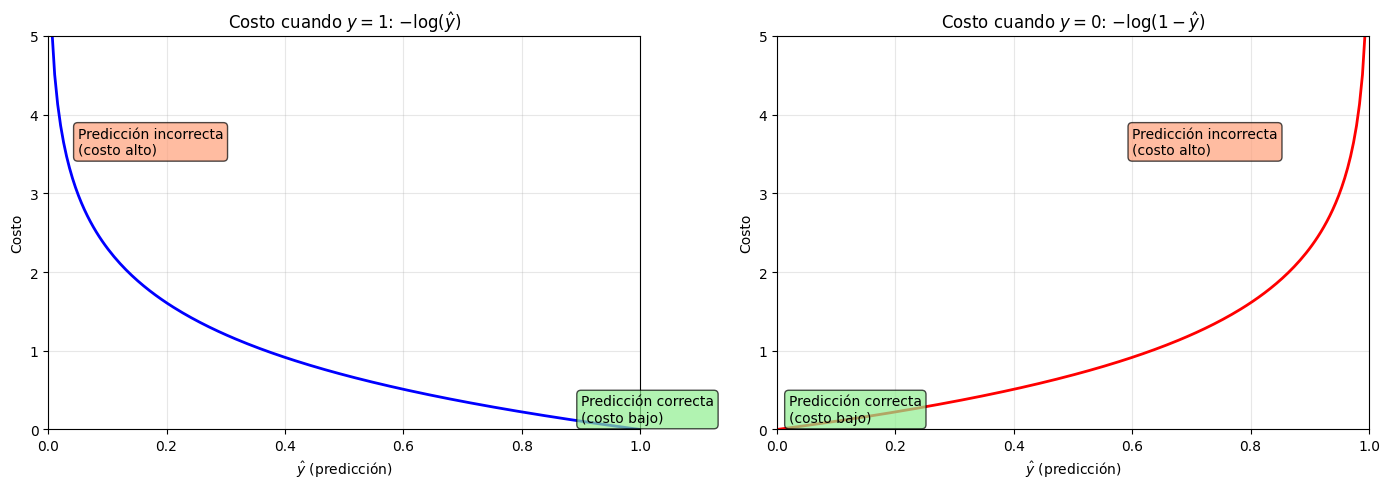

In [6]:
import matplotlib.pyplot as plt
import numpy as np

y_hat = np.linspace(0.001, 0.999, 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Caso y = 1
loss_y1 = -np.log(y_hat)
axes[0].plot(y_hat, loss_y1, 'b-', linewidth=2)
axes[0].set_xlabel('$\hat{y}$ (predicción)')
axes[0].set_ylabel('Costo')
axes[0].set_title('Costo cuando $y = 1$: $-\log(\hat{y})$')
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 5)
axes[0].grid(True, alpha=0.3)
axes[0].annotate('Predicción correcta\n(costo bajo)', xy=(0.9, 0.1), fontsize=10,
                 bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))
axes[0].annotate('Predicción incorrecta\n(costo alto)', xy=(0.05, 3.5), fontsize=10,
                 bbox=dict(boxstyle='round', facecolor='lightsalmon', alpha=0.7))

# Caso y = 0
loss_y0 = -np.log(1 - y_hat)
axes[1].plot(y_hat, loss_y0, 'r-', linewidth=2)
axes[1].set_xlabel('$\hat{y}$ (predicción)')
axes[1].set_ylabel('Costo')
axes[1].set_title('Costo cuando $y = 0$: $-\log(1 - \hat{y})$')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 5)
axes[1].grid(True, alpha=0.3)
axes[1].annotate('Predicción correcta\n(costo bajo)', xy=(0.02, 0.1), fontsize=10,
                 bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))
axes[1].annotate('Predicción incorrecta\n(costo alto)', xy=(0.6, 3.5), fontsize=10,
                 bbox=dict(boxstyle='round', facecolor='lightsalmon', alpha=0.7))

plt.tight_layout()
plt.show()

### Paso 3: Descenso de gradiente

Para minimizar la función de costo, usamos **descenso de gradiente**. Necesitamos calcular las derivadas parciales de $J$ respecto a cada parámetro.

**Gradiente respecto a los pesos $\mathbf{w}$:**

$$
\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i) \cdot \mathbf{x}_i = \frac{1}{n} \mathbf{X}^T (\hat{\mathbf{y}} - \mathbf{y})
$$

**Gradiente respecto al bias $b$:**

$$
\frac{\partial J}{\partial b} = \frac{1}{n} \sum_{i=1}^{n} (\hat{y}_i - y_i)
$$

La **derivación** es la siguiente. Partimos de la regla de la cadena:

$$
\frac{\partial J}{\partial w_j} = \frac{\partial J}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial z} \cdot \frac{\partial z}{\partial w_j}
$$

Donde:

1. $\frac{\partial J}{\partial \hat{y}} = -\frac{y}{\hat{y}} + \frac{1 - y}{1 - \hat{y}}$

2. $\frac{\partial \hat{y}}{\partial z} = \hat{y}(1 - \hat{y})$ (derivada de la sigmoide)

3. $\frac{\partial z}{\partial w_j} = x_j$

Multiplicando:

$$
\frac{\partial J}{\partial w_j} = \left(-\frac{y}{\hat{y}} + \frac{1 - y}{1 - \hat{y}}\right) \cdot \hat{y}(1 - \hat{y}) \cdot x_j = (\hat{y} - y) \cdot x_j
$$

La **regla de actualización** en cada iteración es:

$$
\mathbf{w} \leftarrow \mathbf{w} - \alpha \cdot \frac{\partial J}{\partial \mathbf{w}}
$$

$$
b \leftarrow b - \alpha \cdot \frac{\partial J}{\partial b}
$$

Donde $\alpha$ es el **learning rate** (tasa de aprendizaje).

### Ejemplo numérico

Usemos un ejemplo simplificado con **1 feature** y **3 muestras**.

| $x$ | $y$ |
|-----|-----|
| 1   | 0   |
| 2   | 0   |
| 5   | 1   |

Inicializamos: $w = 0$, $b = 0$, $\alpha = 0.1$

**Iteración 1:**

1. Calcular $z = wx + b$:

$$z_1 = 0 \cdot 1 + 0 = 0, \quad z_2 = 0 \cdot 2 + 0 = 0, \quad z_3 = 0 \cdot 5 + 0 = 0$$

2. Aplicar sigmoide:

$$\hat{y}_1 = \sigma(0) = 0.5, \quad \hat{y}_2 = 0.5, \quad \hat{y}_3 = 0.5$$

3. Calcular errores $(\hat{y}_i - y_i)$:

$$e_1 = 0.5 - 0 = 0.5, \quad e_2 = 0.5 - 0 = 0.5, \quad e_3 = 0.5 - 1 = -0.5$$

4. Calcular gradientes:

$$\frac{\partial J}{\partial w} = \frac{1}{3}(0.5 \cdot 1 + 0.5 \cdot 2 + (-0.5) \cdot 5) = \frac{1}{3}(0.5 + 1.0 - 2.5) = \frac{-1}{3} \approx -0.333$$

$$\frac{\partial J}{\partial b} = \frac{1}{3}(0.5 + 0.5 + (-0.5)) = \frac{0.5}{3} \approx 0.167$$

5. Actualizar parámetros:

$$w \leftarrow 0 - 0.1 \cdot (-0.333) = 0.0333$$

$$b \leftarrow 0 - 0.1 \cdot 0.167 = -0.0167$$

Después de solo una iteración, $w > 0$, lo cual tiene sentido: valores más altos de $x$ están asociados con la clase 1. El proceso se repite miles de veces hasta convergir.

In [7]:
import numpy as np

# Ejemplo numérico paso a paso
X_ej = np.array([1, 2, 5]).reshape(-1, 1)
y_ej = np.array([0, 0, 1])
w, b, lr = 0.0, 0.0, 0.1

print("=== Ejemplo numérico: Descenso de Gradiente ===")
print(f"Datos: X = {X_ej.flatten()}, y = {y_ej}")
print(f"Parámetros iniciales: w = {w}, b = {b}, lr = {lr}\n")

for it in range(5):
    z = w * X_ej.flatten() + b
    y_hat = 1 / (1 + np.exp(-z))
    errors = y_hat - y_ej

    dw = (1 / len(y_ej)) * np.dot(X_ej.flatten(), errors)
    db = (1 / len(y_ej)) * np.sum(errors)

    w -= lr * dw
    b -= lr * db

    loss = -(1 / len(y_ej)) * np.sum(y_ej * np.log(y_hat + 1e-10) + (1 - y_ej) * np.log(1 - y_hat + 1e-10))

    print(f"Iteración {it + 1}:")
    print(f"  ŷ = [{', '.join(f'{v:.4f}' for v in y_hat)}]")
    print(f"  dw = {dw:.4f}, db = {db:.4f}")
    print(f"  w = {w:.4f}, b = {b:.4f}")
    print(f"  Loss = {loss:.4f}\n")

=== Ejemplo numérico: Descenso de Gradiente ===
Datos: X = [1 2 5], y = [0 0 1]
Parámetros iniciales: w = 0.0, b = 0.0, lr = 0.1

Iteración 1:
  ŷ = [0.5000, 0.5000, 0.5000]
  dw = -0.3333, db = 0.1667
  w = 0.0333, b = -0.0167
  Loss = 0.6931

Iteración 2:
  ŷ = [0.5042, 0.5125, 0.5374]
  dw = -0.2612, db = 0.1847
  w = 0.0595, b = -0.0351
  Loss = 0.6803

Iteración 3:
  ŷ = [0.5061, 0.5209, 0.5652]
  dw = -0.2087, db = 0.1974
  w = 0.0803, b = -0.0549
  Loss = 0.6706

Iteración 4:
  ŷ = [0.5064, 0.5264, 0.5858]
  dw = -0.1705, db = 0.2062
  w = 0.0974, b = -0.0755
  Loss = 0.6627

Iteración 5:
  ŷ = [0.5055, 0.5298, 0.6014]
  dw = -0.1426, db = 0.2122
  w = 0.1116, b = -0.0967
  Loss = 0.6557



## Implementación con Código

### Funciones

In [8]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def logistic_regression_fit(X, y, learning_rate=0.001, n_iters=1000):
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0

    for _ in range(n_iters):
        linear_model = np.dot(X, weights) + bias
        y_predicted = sigmoid(linear_model)

        dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
        db = (1 / n_samples) * np.sum(y_predicted - y)

        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias

def logistic_regression_predict(X, weights, bias):
    linear_model = np.dot(X, weights) + bias
    y_predicted = sigmoid(linear_model)
    return np.array([1 if p > 0.5 else 0 for p in y_predicted])

In [9]:
from sklearn.model_selection import train_test_split
from sklearn import datasets

# Cargar datos
bc = datasets.load_breast_cancer()
X, y = bc.data, bc.target

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

# Entrenar
weights, bias = logistic_regression_fit(X_train, y_train, learning_rate=0.0001, n_iters=1000)

# Predecir y evaluar
predictions = logistic_regression_predict(X_test, weights, bias)
accuracy = np.sum(y_test == predictions) / len(y_test)
print(f"Logistic Regression accuracy: {accuracy:.4f}")

Logistic Regression accuracy: 0.9298


### Clase

In [10]:
import numpy as np
import matplotlib.pyplot as plt


class LogisticRegression:
    def __init__(self, learning_rate=0.001, n_iters=1000):
        self.lr = learning_rate
        self.n_iters = n_iters
        self.weights = None
        self.bias = None
        self.losses = []

    def fit(self, X, y):
        """Entrena el modelo con descenso de gradiente"""
        n_samples, n_features = X.shape

        # Inicializar parámetros
        self.weights = np.zeros(n_features)
        self.bias = 0
        self.losses = []

        # Descenso de gradiente
        for _ in range(self.n_iters):
            # Modelo lineal + sigmoide
            linear_model = np.dot(X, self.weights) + self.bias
            y_predicted = self._sigmoid(linear_model)

            # Calcular gradientes
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            # Actualizar parámetros
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            # Registrar loss
            loss = self._compute_loss(y, y_predicted)
            self.losses.append(loss)

    def predict(self, X):
        """Predice clases (0 o 1)"""
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self._sigmoid(linear_model)
        return np.array([1 if i > 0.5 else 0 for i in y_predicted])

    def predict_proba(self, X):
        """Retorna las probabilidades predichas"""
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def score(self, X, y):
        """Calcula la accuracy del modelo"""
        predictions = self.predict(X)
        return np.sum(predictions == y) / len(y)

    def plot_loss(self):
        """Grafica la evolución del loss durante el entrenamiento"""
        plt.figure(figsize=(8, 5))
        plt.plot(self.losses, 'b-', linewidth=1)
        plt.xlabel('Iteración')
        plt.ylabel('Loss (Binary Cross-Entropy)')
        plt.title('Evolución del Loss durante el entrenamiento')
        plt.grid(True, alpha=0.3)
        plt.show()

    @staticmethod
    def _sigmoid(x):
        return 1 / (1 + np.exp(-x))

    @staticmethod
    def _compute_loss(y_true, y_pred):
        epsilon = 1e-10
        return -np.mean(y_true * np.log(y_pred + epsilon) + (1 - y_true) * np.log(1 - y_pred + epsilon))

Logistic Regression accuracy: 0.9298


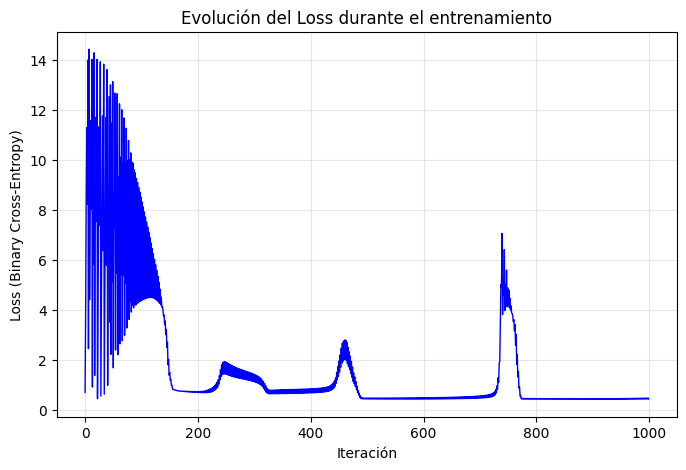

In [11]:
from sklearn.model_selection import train_test_split
from sklearn import datasets

# Cargar datos
bc = datasets.load_breast_cancer()
X, y = bc.data, bc.target

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

# Crear y entrenar modelo
model = LogisticRegression(learning_rate=0.0001, n_iters=1000)
model.fit(X_train, y_train)

# Evaluar
acc = model.score(X_test, y_test)
print(f"Logistic Regression accuracy: {acc:.4f}")

# Visualizar evolución del loss
model.plot_loss()

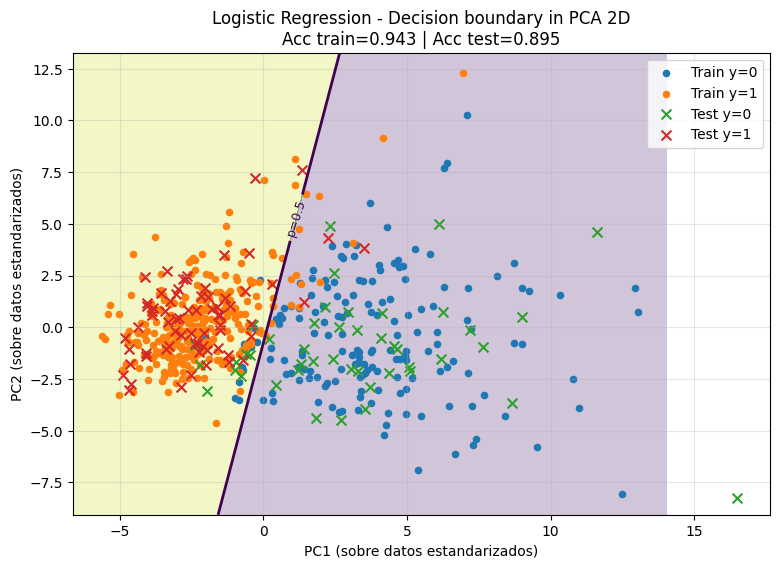

In [21]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def plot_logistic_decision_boundary_2d(model_class, X_train, y_train, X_test, y_test,
                                      learning_rate=1e-4, n_iters=2000,
                                      grid_step=0.02, title="Logistic Regression - Decision boundary in PCA 2D"):

    # 1) Estandarizar (muy recomendado para GD y para PCA)
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s  = scaler.transform(X_test)

    # 2) PCA a 2D para VISUALIZACIÓN
    pca = PCA(n_components=2, random_state=1234)
    X_train_2d = pca.fit_transform(X_train_s)
    X_test_2d  = pca.transform(X_test_s)

    # 3) Entrenar tu modelo en 2D
    model_2d = model_class(learning_rate=learning_rate, n_iters=n_iters)
    model_2d.fit(X_train_2d, y_train)

    acc_train = model_2d.score(X_train_2d, y_train)
    acc_test  = model_2d.score(X_test_2d, y_test)

    # 4) Crear grilla para regiones de decisión
    x_min, x_max = X_train_2d[:, 0].min() - 1.0, X_train_2d[:, 0].max() + 1.0
    y_min, y_max = X_train_2d[:, 1].min() - 1.0, X_train_2d[:, 1].max() + 1.0

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, grid_step),
        np.arange(y_min, y_max, grid_step)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]

    # Probabilidades en la grilla
    probs = model_2d.predict_proba(grid).reshape(xx.shape)

    # Regiones (umbral 0.5) + frontera p=0.5
    plt.figure(figsize=(9, 6))
    plt.contourf(xx, yy, (probs >= 0.5).astype(int), alpha=0.25)  # regiones
    cs = plt.contour(xx, yy, probs, levels=[0.5], linewidths=2)  # frontera
    plt.clabel(cs, fmt={0.5: "p=0.5"}, inline=True, fontsize=9)

    # Puntos: train y test con marcadores distintos
    plt.scatter(X_train_2d[y_train == 0, 0], X_train_2d[y_train == 0, 1], s=20, marker='o', label="Train y=0")
    plt.scatter(X_train_2d[y_train == 1, 0], X_train_2d[y_train == 1, 1], s=20, marker='o', label="Train y=1")
    plt.scatter(X_test_2d[y_test == 0, 0],  X_test_2d[y_test == 0, 1],  s=50, marker='x', label="Test y=0")
    plt.scatter(X_test_2d[y_test == 1, 0],  X_test_2d[y_test == 1, 1],  s=50, marker='x', label="Test y=1")

    plt.xlabel("PC1 (sobre datos estandarizados)")
    plt.ylabel("PC2 (sobre datos estandarizados)")
    plt.title(f"{title}\nAcc train={acc_train:.3f} | Acc test={acc_test:.3f}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

    return model_2d, scaler, pca


#
model_2d, scaler_2d, pca_2d = plot_logistic_decision_boundary_2d(
    LogisticRegression,
    X_train, y_train,
    X_test, y_test,
    learning_rate=1e-4,
    n_iters=4000
)

In [12]:
# Comparar diferentes learning rates
print("Comparación de diferentes learning rates (1000 iteraciones):\n")
for lr in [0.00001, 0.0001, 0.001, 0.01]:
    model = LogisticRegression(learning_rate=lr, n_iters=1000)
    model.fit(X_train, y_train)
    acc = model.score(X_test, y_test)
    print(f"  lr = {lr}: accuracy = {acc:.4f}, final loss = {model.losses[-1]:.4f}")

Comparación de diferentes learning rates (1000 iteraciones):

  lr = 1e-05: accuracy = 0.9211, final loss = 0.2578
  lr = 0.0001: accuracy = 0.9298, final loss = 0.4337
  lr = 0.001: accuracy = 0.8947, final loss = 1.6627


/tmp/ipykernel_3434/2265014159.py:68: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))


  lr = 0.01: accuracy = 0.9211, final loss = 2.6993
